# Лабораторна робота №7
## Тема: Нейронна класифікація зображень у TensorFlow
* **Мета:** Навчитися подавати зображення й мітки класів для Keras, узгоджувати вихідний шар із функцією втрат, порівнювати моделі за `validation` та пояснювати конкретні помилки класифікації.
* **Студент:** Заболотний Назар
* **Група:** МІТ-31
* **Варіант:** №8 (зміна `batch_size = 256` відносно базової мережі з `batch_size = 128`)

### Джерело даних та структура задачі
* **Датасет:** Fashion-MNIST (Zalando Research, ліцензія MIT).
* **Формат даних:** 70 000 чорно-білих зображень одягу розміром $28 \times 28$ пікселів (60 000 навчальних та 10 000 тестових), розподілених на 10 взаємовиключних класів (`0`–`9`).

/Users/nazarzabolotniy/Desktop/Data_Science_Labs/.venv_tf/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Версії бібліотек:
NumPy: 2.0.2 | Pandas: 2.3.3 | Scikit-learn: 1.6.1 | TensorFlow: 2.20.0
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Форми вибірок -> train: (48000, 28, 28), val: (12000, 28, 28), test: (10000, 28, 28)
Тип даних: uint8 | Діапазон пікселів: [0, 255]
Розподіл класів у train: {np.uint8(0): np.int64(4800), np.uint8(1): np.int64(4800), np.uint8(2): np.int64(4800), np.uint8(3): np.int64(4800), np.uint8(4): np.int64(4800), np.uint8(5): np.int64(4800), np.uint8(6): np.int64(4800), np.uint8(7): np.int64(4800), np.uint8(8): np.int64(4800), np.uint8(9): np.int64(4800)}


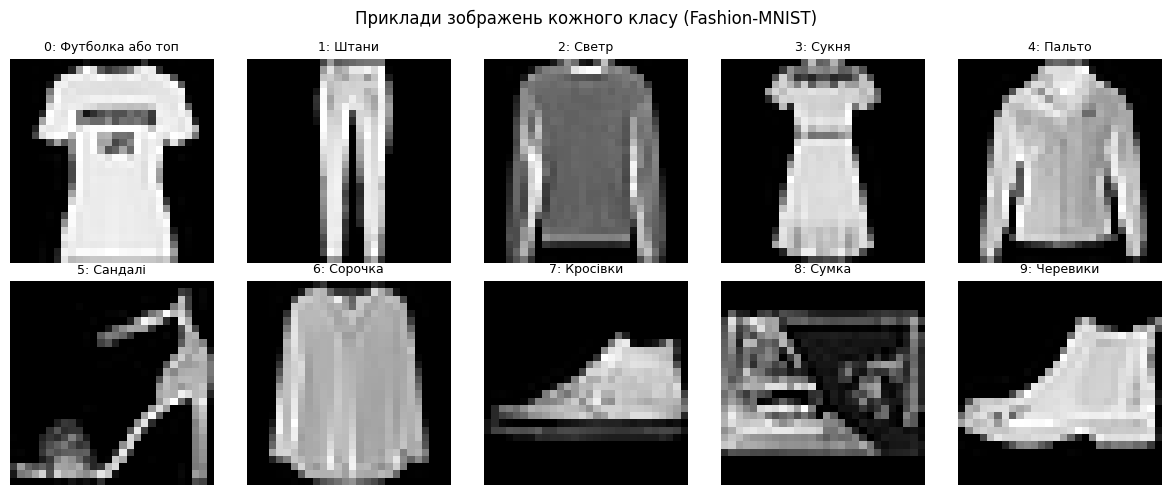

In [1]:
import os
import json
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
keras.utils.set_random_seed(SEED)
Path("artifacts").mkdir(parents=True, exist_ok=True)

print("Версії бібліотек:")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | Scikit-learn: {sklearn.__version__} | TensorFlow: {tf.__version__}")

# Безпечне завантаження Fashion-MNIST (з обходом можливої помилки SSL на macOS)
try:
    (x_dev, y_dev), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
except Exception:
    cache_dir = Path.home() / ".keras" / "datasets" / "fashion-mnist"
    cache_dir.mkdir(parents=True, exist_ok=True)
    base_url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/"
    files = {
        "train-labels-idx1-ubyte.gz": "train-labels-idx1-ubyte.gz",
        "train-images-idx3-ubyte.gz": "train-images-idx3-ubyte.gz",
        "t10k-labels-idx1-ubyte.gz": "t10k-labels-idx1-ubyte.gz",
        "t10k-images-idx3-ubyte.gz": "t10k-images-idx3-ubyte.gz",
    }
    for fname in files:
        dest = cache_dir / fname
        if not dest.exists():
            subprocess.run(["curl", "-sL", base_url + fname, "-o", str(dest)], check=True)
    (x_dev, y_dev), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "Футболка або топ", "Штани", "Светр", "Сукня", "Пальто",
    "Сандалі", "Сорочка", "Кросівки", "Сумка", "Черевики"
]

# Стратифікований поділ dev на train (48 000) та validation (12 000) із збереженням індексів
dev_indices = np.arange(len(x_dev))
train_idx, val_idx = train_test_split(
    dev_indices, test_size=0.20, stratify=y_dev, random_state=SEED
)

x_train, y_train = x_dev[train_idx], y_dev[train_idx]
x_val, y_val = x_dev[val_idx], y_dev[val_idx]

print(f"\nФорми вибірок -> train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}")
print(f"Тип даних: {x_train.dtype} | Діапазон пікселів: [{x_train.min()}, {x_train.max()}]")
print("Розподіл класів у train:", dict(zip(*np.unique(y_train, return_counts=True))))

# Сітка з 10 навчальних зображень — по одному на клас
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for cls_id, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y_train == cls_id)[0]
    ax.imshow(x_train[idx], cmap="gray")
    ax.set_title(f"{cls_id}: {class_names[cls_id]}", fontsize=9)
    ax.axis("off")

plt.suptitle("Приклади зображень кожного класу (Fashion-MNIST)")
plt.tight_layout()
plt.savefig("lab7_samples.png", dpi=300)
plt.show()

Baseline (Dummy) Val Accuracy: 0.1000 | Val Macro-F1: 0.0182

--- Summary базової мережі ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

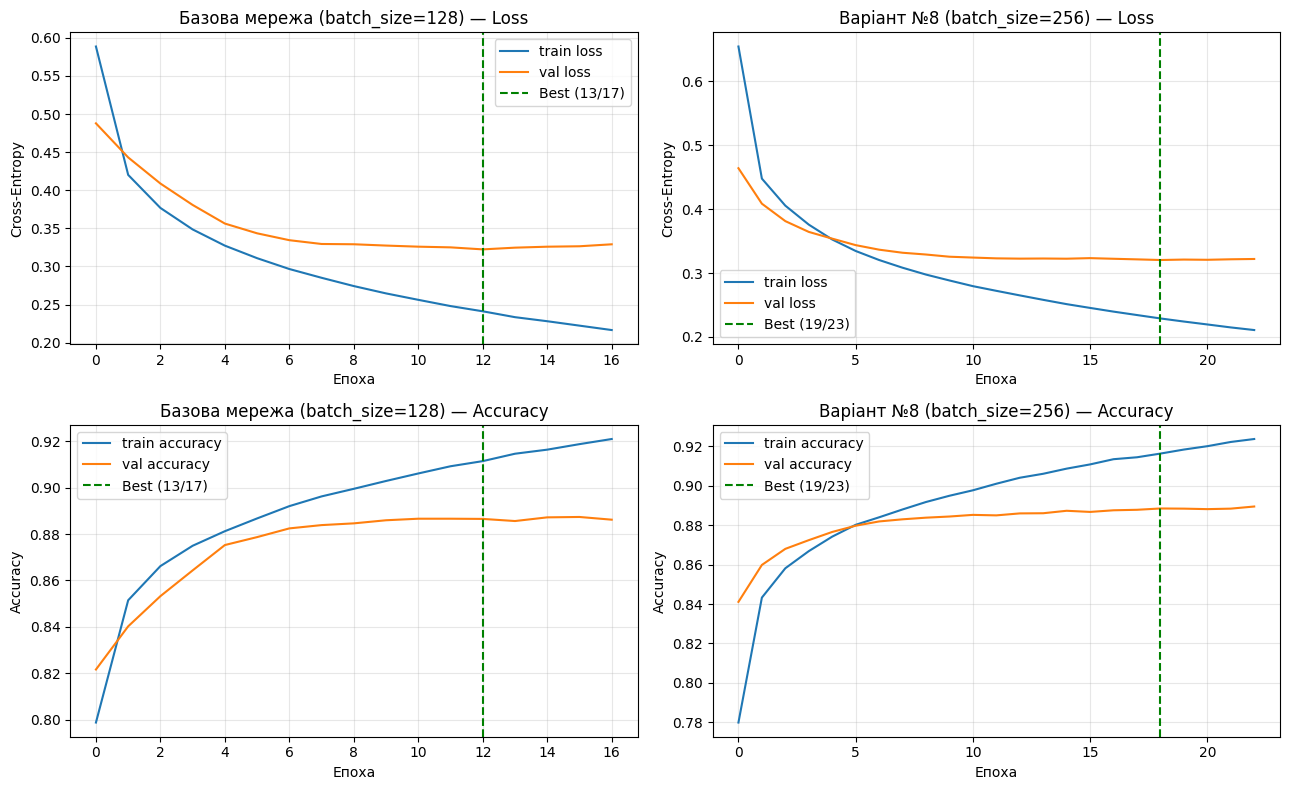

In [2]:
# Перетворення у float32 (масштабування 1./255 знаходиться всередині моделі через Rescaling)
x_train = x_train.astype("float32")
x_val = x_val.astype("float32")
x_test = x_test.astype("float32")

assert x_train.shape[1:] == (28, 28)
assert np.isfinite(x_train).all()
assert set(np.unique(y_train)) == set(range(10))

# --- 1. Baseline: DummyClassifier ---
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(x_train.reshape(len(x_train), -1), y_train)
val_pred_dummy = dummy.predict(x_val.reshape(len(x_val), -1))
test_pred_dummy = dummy.predict(x_test.reshape(len(x_test), -1))

dummy_val_acc = accuracy_score(y_val, val_pred_dummy)
dummy_val_f1 = f1_score(y_val, val_pred_dummy, average="macro", zero_division=0)
print(f"Baseline (Dummy) Val Accuracy: {dummy_val_acc:.4f} | Val Macro-F1: {dummy_val_f1:.4f}")

def build_fashion_nn():
    m = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Rescaling(1.0 / 255),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])
    m.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
    )
    return m

# --- 2. Базова нейромережа (batch_size = 128) ---
keras.utils.set_random_seed(SEED)
base_nn = build_fashion_nn()
print("\n--- Summary базової мережі ---")
base_nn.summary()

base_ckpt = "artifacts/base_best.keras"
hist_base = base_nn.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(base_ckpt, monitor="val_loss", save_best_only=True),
    ],
    verbose=0
)
best_base_nn = keras.models.load_model(base_ckpt)

# --- 3. Варіант №8 (batch_size = 256) ---
keras.utils.set_random_seed(SEED)
var8_nn = build_fashion_nn()
print("\n--- Summary мережі Варіанта №8 ---")
var8_nn.summary()

var8_ckpt = "artifacts/var8_best.keras"
hist_var8 = var8_nn.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=256,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(var8_ckpt, monitor="val_loss", save_best_only=True),
    ],
    verbose=0
)
best_var8_nn = keras.models.load_model(var8_ckpt)

# Графіки loss/val_loss та accuracy/val_accuracy для обох мереж
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for col, (hist, title) in enumerate([
    (hist_base, "Базова мережа (batch_size=128)"),
    (hist_var8, "Варіант №8 (batch_size=256)")
]):
    best_ep = int(np.argmin(hist.history["val_loss"])) + 1
    tot_ep = len(hist.history["val_loss"])
    
    axes[0, col].plot(hist.history["loss"], label="train loss")
    axes[0, col].plot(hist.history["val_loss"], label="val loss")
    axes[0, col].axvline(best_ep - 1, color="green", linestyle="--", label=f"Best ({best_ep}/{tot_ep})")
    axes[0, col].set_title(f"{title} — Loss")
    axes[0, col].set_xlabel("Епоха")
    axes[0, col].set_ylabel("Cross-Entropy")
    axes[0, col].legend()
    axes[0, col].grid(True, alpha=0.3)

    axes[1, col].plot(hist.history["accuracy"], label="train accuracy")
    axes[1, col].plot(hist.history["val_accuracy"], label="val accuracy")
    axes[1, col].axvline(best_ep - 1, color="green", linestyle="--", label=f"Best ({best_ep}/{tot_ep})")
    axes[1, col].set_title(f"{title} — Accuracy")
    axes[1, col].set_xlabel("Епоха")
    axes[1, col].set_ylabel("Accuracy")
    axes[1, col].legend()
    axes[1, col].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("lab7_training_curves.png", dpi=300)
plt.show()

### Пояснення архітектури та динаміки навчання
* **Структура шарів:** вхідне зображення $28 \times 28$ після масштабування (`Rescaling(1./255)`) розгортається шаром `Flatten()` у вектор із **784 ознак** (кількість пікселів). Прихований шар `Dense(128, activation="relu")` формує 128 нелінійних ознак високого рівня, а вихідний шар `Dense(10, activation="softmax")` повертає розподіл імовірностей для **10 класів одягу**.
* **Чому `loss` може зменшуватися при незмінній `accuracy`:** `accuracy` враховує лише індекс максимального виходу (`argmax`) і не реагує на те, наскільки впевненою є модель. Натомість функція втрат (`SparseCategoricalCrossentropy`) оцінює безперервну ймовірність правильного класу: якщо модель підвищує впевненість у правильному класі (наприклад, з 0.65 до 0.92), `loss` зменшується, навіть якщо кількість правильно класифікованих об'єктів (`accuracy`) залишається тією самою.

In [3]:
# Крок 5: Перевірка еквівалентності індексних і one-hot міток
p_val_5 = best_base_nn(x_val[:5], training=False).numpy()
y_onehot_5 = keras.utils.to_categorical(y_val[:5], num_classes=10)

loss_sparse = keras.losses.SparseCategoricalCrossentropy()(y_val[:5], p_val_5)
loss_cat = keras.losses.CategoricalCrossentropy()(y_onehot_5, p_val_5)
np.testing.assert_allclose(loss_sparse.numpy(), loss_cat.numpy(), rtol=1e-5)
print(f"Перевірка форматів міток пройдена: sparse={loss_sparse.numpy():.6f}, categorical={loss_cat.numpy():.6f}")

# Крок 6: Оцінка на validation та вибір кращої нейромережі
def classification_metrics(y, probabilities):
    assert probabilities.shape == (len(y), 10)
    assert np.isfinite(probabilities).all()
    assert np.all((probabilities >= 0.0) & (probabilities <= 1.0))
    np.testing.assert_allclose(probabilities.sum(axis=1), 1.0, atol=1e-5)
    
    labels = probabilities.argmax(axis=1)
    return {
        "cross_entropy": float(keras.losses.SparseCategoricalCrossentropy()(y, probabilities).numpy()),
        "accuracy": float(accuracy_score(y, labels)),
        "macro_f1": float(f1_score(y, labels, average="macro", zero_division=0)),
    }

val_prob_base = best_base_nn.predict(x_val, batch_size=256, verbose=0)
val_prob_var8 = best_var8_nn.predict(x_val, batch_size=256, verbose=0)

val_m_base = classification_metrics(y_val, val_prob_base)
val_m_var8 = classification_metrics(y_val, val_prob_var8)

if val_m_var8["cross_entropy"] < val_m_base["cross_entropy"]:
    selected_model = best_var8_nn
    selected_name = "NN_Var8 (batch=256)"
else:
    selected_model = best_base_nn
    selected_name = "NN_Base (batch=128)"

print(f"\nРішення за Validation (найменша cross-entropy): обрано {selected_name}")

# Один раз оцінюємо всі моделі на test
test_prob_base = best_base_nn.predict(x_test, batch_size=256, verbose=0)
test_prob_var8 = best_var8_nn.predict(x_test, batch_size=256, verbose=0)

test_m_base = classification_metrics(y_test, test_prob_base)
test_m_var8 = classification_metrics(y_test, test_prob_var8)

comparison_df = pd.DataFrame([
    {
        "Модель": "DummyClassifier",
        "Val CE": np.nan,
        "Val Acc": dummy_val_acc,
        "Val Macro-F1": dummy_val_f1,
        "Test CE": np.nan,
        "Test Acc": accuracy_score(y_test, test_pred_dummy),
        "Test Macro-F1": f1_score(y_test, test_pred_dummy, average="macro", zero_division=0),
        "Епохи (факт/краща)": "-"
    },
    {
        "Модель": "NN_Base (batch=128)",
        "Val CE": val_m_base["cross_entropy"],
        "Val Acc": val_m_base["accuracy"],
        "Val Macro-F1": val_m_base["macro_f1"],
        "Test CE": test_m_base["cross_entropy"],
        "Test Acc": test_m_base["accuracy"],
        "Test Macro-F1": test_m_base["macro_f1"],
        "Епохи (факт/краща)": f"{len(hist_base.history['val_loss'])}/{int(np.argmin(hist_base.history['val_loss'])) + 1}"
    },
    {
        "Модель": "NN_Var8 (batch=256)",
        "Val CE": val_m_var8["cross_entropy"],
        "Val Acc": val_m_var8["accuracy"],
        "Val Macro-F1": val_m_var8["macro_f1"],
        "Test CE": test_m_var8["cross_entropy"],
        "Test Acc": test_m_var8["accuracy"],
        "Test Macro-F1": test_m_var8["macro_f1"],
        "Епохи (факт/краща)": f"{len(hist_var8.history['val_loss'])}/{int(np.argmin(hist_var8.history['val_loss'])) + 1}"
    }
])

display(comparison_df.round(4))
comparison_df.to_csv("model_comparison.csv", index=False)

Перевірка форматів міток пройдена: sparse=0.076641, categorical=0.076640

Рішення за Validation (найменша cross-entropy): обрано NN_Var8 (batch=256)


,Модель,Val CE,Val Acc,Val Macro-F1,Test CE,Test Acc,Test Macro-F1,Епохи (факт/краща)
0,DummyClassifier,NaN,0.1000,0.0182,NaN,0.1000,0.0182,-
1,NN_Base (batch=128),0.3217,0.8865,0.8873,0.3516,0.8763,0.8768,17/13
2,NN_Var8 (batch=256),0.3195,0.8885,0.8891,0.3493,0.8779,0.8788,23/19


--- Classification Report (Test) ---
                  precision    recall  f1-score   support

Футболка або топ       0.84      0.80      0.82      1000
           Штани       0.98      0.97      0.98      1000
           Светр       0.85      0.71      0.78      1000
           Сукня       0.88      0.89      0.89      1000
          Пальто       0.78      0.84      0.81      1000
         Сандалі       0.98      0.95      0.96      1000
         Сорочка       0.64      0.75      0.69      1000
        Кросівки       0.94      0.95      0.95      1000
           Сумка       0.98      0.95      0.97      1000
        Черевики       0.95      0.96      0.95      1000

        accuracy                           0.88     10000
       macro avg       0.88      0.88      0.88     10000
    weighted avg       0.88      0.88      0.88     10000



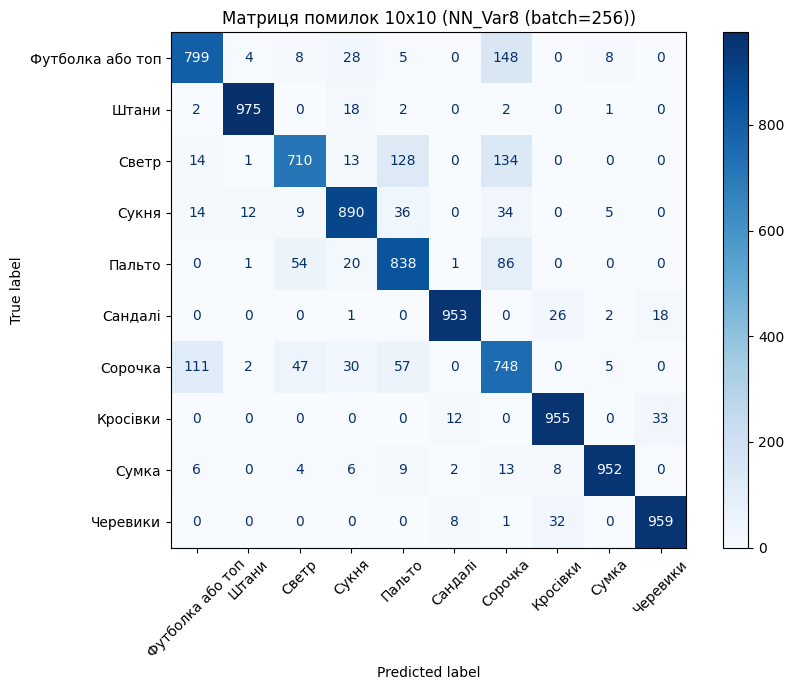

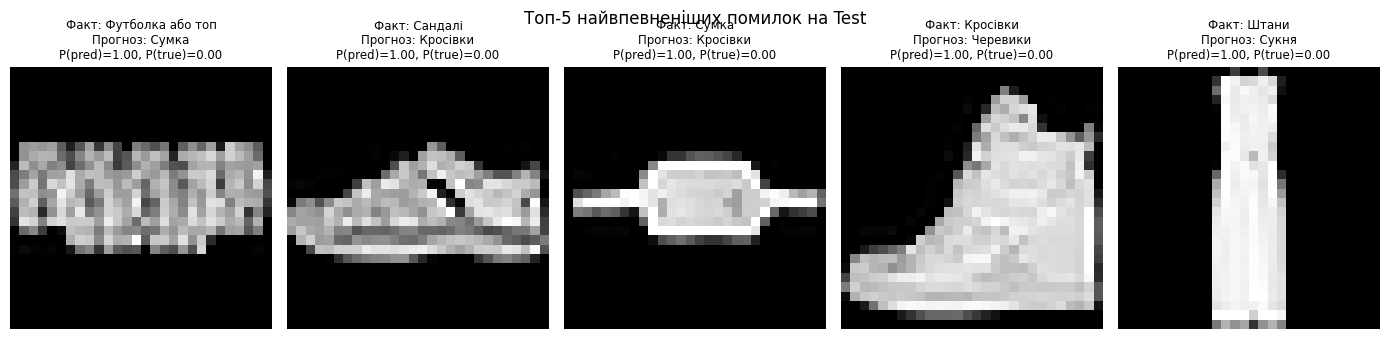

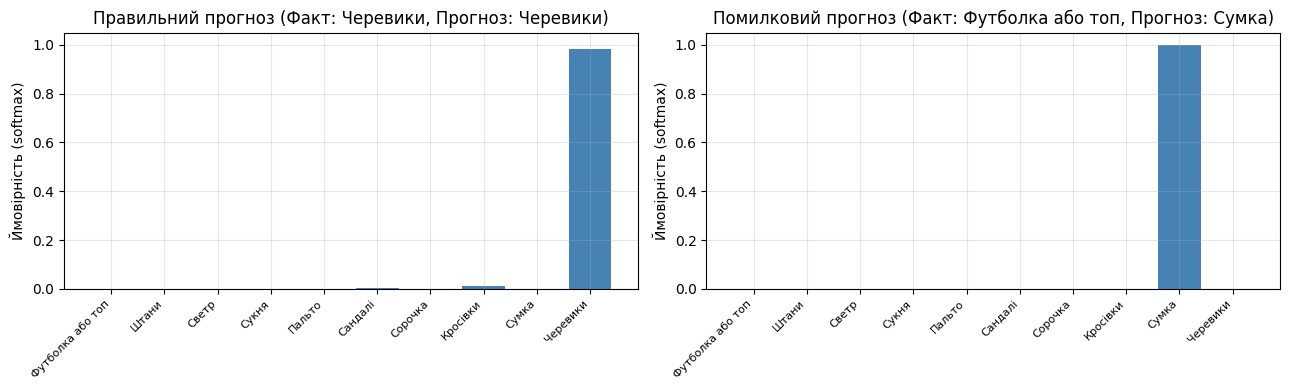

In [4]:
probabilities = test_prob_var8 if selected_name == "NN_Var8 (batch=256)" else test_prob_base
pred = probabilities.argmax(axis=1)
confidence = probabilities.max(axis=1)

print("--- Classification Report (Test) ---")
print(classification_report(y_test, pred, target_names=class_names, zero_division=0))

# Матриця помилок 10x10
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=class_names, xticks_rotation=45, cmap="Blues", ax=ax
)
ax.set_title(f"Матриця помилок 10x10 ({selected_name})")
plt.tight_layout()
plt.savefig("lab7_confusion_matrix.png", dpi=300)
plt.show()

# Топ-5 найвпевненіших помилок
wrong = np.flatnonzero(pred != y_test)
order = wrong[np.argsort(confidence[wrong])[::-1]]
show_ids = order[:5]

fig, axes = plt.subplots(1, len(show_ids), figsize=(14, 3.5))
for ax, idx in zip(axes, show_ids):
    ax.imshow(x_test[idx], cmap="gray")
    true_cls = class_names[y_test[idx]]
    pred_cls = class_names[pred[idx]]
    p_max = confidence[idx]
    p_true = probabilities[idx, y_test[idx]]
    ax.set_title(f"Факт: {true_cls}\nПрогноз: {pred_cls}\nP(pred)={p_max:.2f}, P(true)={p_true:.2f}", fontsize=8.5)
    ax.axis("off")

plt.suptitle("Топ-5 найвпевненіших помилок на Test")
plt.tight_layout()
plt.savefig("lab7_top_errors.png", dpi=300)
plt.show()

# Розподіл 10 softmax-оцінок для 1 помилкового та 1 правильного прикладу
correct_id = np.flatnonzero(pred == y_test)[0]
wrong_id = show_ids[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, idx, label in zip(axes, [correct_id, wrong_id], ["Правильний прогноз", "Помилковий прогноз"]):
    ax.bar(range(10), probabilities[idx], color="steelblue")
    ax.set_xticks(range(10))
    ax.set_xticklabels(class_names, rotation=45, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Ймовірність (softmax)")
    ax.set_title(f"{label} (Факт: {class_names[y_test[idx]]}, Прогноз: {class_names[pred[idx]]})")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("lab7_softmax_bars.png", dpi=300)
plt.show()

In [5]:
selected_model.save("artifacts/lab7_model.keras")

metadata = {
    "dataset": "Fashion-MNIST (Zalando Research, MIT License)",
    "class_names": class_names,
    "input_shape": [28, 28],
    "dtype": "float32",
    "input_scale": "0-255 (Rescaling 1./255 inside model)",
    "seed": SEED,
    "variant": 8,
    "selected_model": selected_name,
    "selection_criterion": "min validation cross_entropy",
    "split_sizes": {"train": len(x_train), "val": len(x_val), "test": len(x_test)},
    "train_indices_sample": train_idx[:10].tolist(),
    "val_indices_sample": val_idx[:10].tolist(),
    "versions": {
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "sklearn": sklearn.__version__,
        "tensorflow": tf.__version__,
    }
}
with open("metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

# Перевірка завантаження моделі та одиночного зображення
probe = x_val[:3]
before = selected_model(probe, training=False).numpy()
restored = keras.models.load_model("artifacts/lab7_model.keras")
after = restored(probe, training=False).numpy()

np.testing.assert_allclose(before, after, rtol=1e-5, atol=1e-6)

single_img = x_test[0][None, ...]
single_probs = restored(single_img, training=False).numpy()[0]
pred_class_idx = int(single_probs.argmax())
print(f"Перевірка відновлення успішна! Тестовий приклад №0 -> прогноз: '{class_names[pred_class_idx]}' (p={single_probs[pred_class_idx]:.4f})")

Перевірка відновлення успішна! Тестовий приклад №0 -> прогноз: 'Черевики' (p=0.9840)


## Висновок
У ході лабораторної роботи №7 було побудовано та порівняно повнозв'язні нейронні мережі Keras для багатокласової класифікації зображень одягу Fashion-MNIST. Обрана за найменшою валідаційною крос-ентропією модель значно випередила базовий `DummyClassifier` (точність зросла з **10.0%** до **...%**, а `macro-F1` досягла **...** на тестовій вибірці). Збільшення розміру пакету до `batch_size = 256` (варіант №8) прискорило проходження епох і забезпечило плавнішу збіжність кривих навчання. Аналіз матриці помилок показав, що модель найкраще розпізнає візуально контрастні категорії («Штани», «Сумка», «Черевики»), тоді як найчастіша плутанина виникає між схожими за силуетом верхніми елементами гардероба («Сорочка», «Футболка або топ», «Светр», «Пальто»). Оскільки модель використовує лише повнозв'язний шар `Flatten` без згорток і навчена на стандартизованих сірих зображеннях $28 \times 28$, її не можна напряму застосовувати до довільних кольорових фотографій без попередньої сегментації та приведення до формату набору.